<a href="https://colab.research.google.com/github/esashika/esashika_academy/blob/main/TF_IDF_%2B_CountVectorizer.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Esashika Academy**

**Autor:** Rhedson Esashika

**Linkedin:** https://www.linkedin.com/in/esashika/

In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("jp797498e/twitter-entity-sentiment-analysis")

print("Path to dataset files:", path)

Path to dataset files: /root/.cache/kagglehub/datasets/jp797498e/twitter-entity-sentiment-analysis/versions/2


In [ ]:
import pandas as pd
df_training = pd.read_csv(path + "/twitter_training.csv")
df_validation = pd.read_csv(path + "/twitter_validation.csv")
df_training.columns = ["id", "local", "sentiment", "text"]
df_validation.columns = ["id", "local", "sentiment", "text"]

df = pd.concat([df_training, df_validation], ignore_index=True)
df = df.drop(columns=['id']).reset_index(drop=True)
df = df.dropna(subset=['text'])
df = df.dropna(subset=['sentiment'])
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 74994 entries, 0 to 75679
Data columns (total 3 columns):
 #   Column     Non-Null Count  Dtype 
---  ------     --------------  ----- 
 0   local      74994 non-null  object
 1   sentiment  74994 non-null  object
 2   text       74994 non-null  object
dtypes: object(3)
memory usage: 2.3+ MB


In [ ]:
import re
import string
import nltk
import pandas as pd
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.stem import WordNetLemmatizer

# Baixar recursos do NLTK (executado apenas uma vez)
nltk.download('punkt')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('punkt_tab')

# Classe de Pré-processamento de Tweets
class TweetPreprocessor:
    def __init__(self, language='english'):
        self.stop_words = set(stopwords.words(language))  # Stopwords do idioma
        self.lemmatizer = WordNetLemmatizer()

    def clean_text(self, text):
        """Remove URLs, menções, hashtags, números e caracteres especiais"""
        text = str(text).lower()  # Converter para minúsculas
        text = re.sub(r'http\S+|www\S+', '', text)  # Remover URLs
        text = re.sub(r'@\w+', '', text)  # Remover menções (@usuario)
        text = re.sub(r'#\w+', '', text)  # Remover hashtags
        text = re.sub(r'\d+', '', text)  # Remover números
        text = text.translate(str.maketrans('', '', string.punctuation))  # Remover pontuação
        return text

    def tokenize_and_lemmatize(self, text):
        """Tokeniza, remove stopwords e aplica lematização"""
        tokens = word_tokenize(text)  # Tokenização
        tokens = [word for word in tokens if word not in self.stop_words]  # Remover stopwords
        tokens = [self.lemmatizer.lemmatize(word) for word in tokens]  # Lematização
        return " ".join(tokens)  # Rejuntar tokens

    def preprocess(self, text):
        """Executa todo o pipeline de pré-processamento"""
        text = self.clean_text(text)
        text = self.tokenize_and_lemmatize(text)
        return text

# Aplicação da limpeza ao DataFrame
# Criar o pre-processador
preprocessor = TweetPreprocessor()

# Aplicar o pré-processamento à coluna 'text' do DataFrame
df['clean_text'] = df['text'].apply(preprocessor.preprocess)

[nltk_data] Downloading package punkt to /root/nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data]   Package wordnet is already up-to-date!
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Package punkt_tab is already up-to-date!


 Acurácia do Modelo: 0.49

 Relatório de Classificação:
              precision    recall  f1-score   support

    Negative       0.48      0.69      0.57      4525
    Positive       0.51      0.55      0.53      4186
     Neutral       0.50      0.38      0.43      3679
  Irrelevant       0.40      0.17      0.24      2609

    accuracy                           0.49     14999
   macro avg       0.47      0.45      0.44     14999
weighted avg       0.48      0.49      0.47     14999



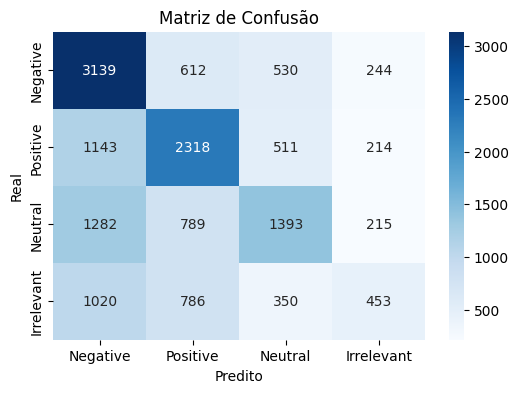

In [ ]:
import pandas as pd
import numpy as np
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

# Remover valores nulos no texto e sentimento
df = df.dropna(subset=['clean_text', 'sentiment']).reset_index(drop=True)

# Atualizando o mapeamento dos sentimentos
sentiment_map = {'Positive': 1, 'Negative': 0, 'Neutral': 2, 'Irrelevant': 3}
df['sentiment'] = df['sentiment'].map(sentiment_map)

# Verificar se ainda existem NaNs após o mapeamento
df = df.dropna(subset=['sentiment'])  # Caso alguma categoria não esteja mapeada
df['sentiment'] = df['sentiment'].astype(int)  # Garantir que os valores sejam inteiros

# Vetorização TF-IDF
vectorizer = TfidfVectorizer(stop_words='english', max_features=200)
X = vectorizer.fit_transform(df['clean_text'])

# Convertendo os sentimentos para array NumPy
y = df['sentiment']

# Divisão dos dados (80% treino, 20% teste)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Treinamento do modelo
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# Previsões
y_pred = model.predict(X_test)

# Avaliação do modelo
accuracy = accuracy_score(y_test, y_pred)
print(f" Acurácia do Modelo: {accuracy:.2f}")

# Relatório de Classificação
print("\n Relatório de Classificação:")
print(classification_report(y_test, y_pred, target_names=['Negative', 'Positive', 'Neutral', 'Irrelevant']))

# Matriz de Confusão
plt.figure(figsize=(6, 4))
sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt='d', cmap="Blues",
            xticklabels=['Negative', 'Positive', 'Neutral', 'Irrelevant'],
            yticklabels=['Negative', 'Positive', 'Neutral', 'Irrelevant'])
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão")
plt.show()


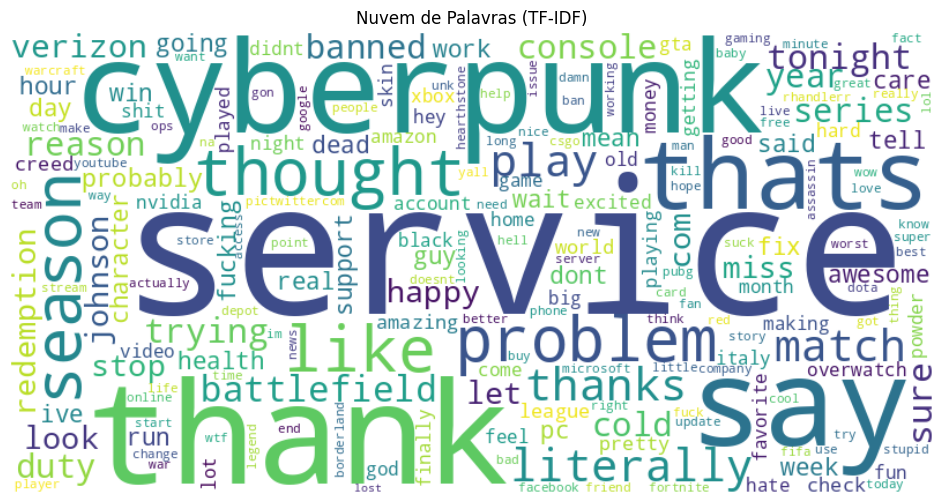

In [ ]:
import matplotlib.pyplot as plt
from wordcloud import WordCloud

# Somar os valores de TF-IDF por palavra
word_freq = dict(zip(vectorizer.get_feature_names_out(), tfidf_matrix.sum(axis=0).tolist()[0]))

# Gerar a WordCloud
wordcloud = WordCloud(width=800, height=400, background_color='white').generate_from_frequencies(word_freq)

# Exibir a WordCloud
plt.figure(figsize=(12, 6))
plt.imshow(wordcloud, interpolation='bilinear')
plt.axis("off")
plt.title("Nuvem de Palavras (TF-IDF)")
plt.show()

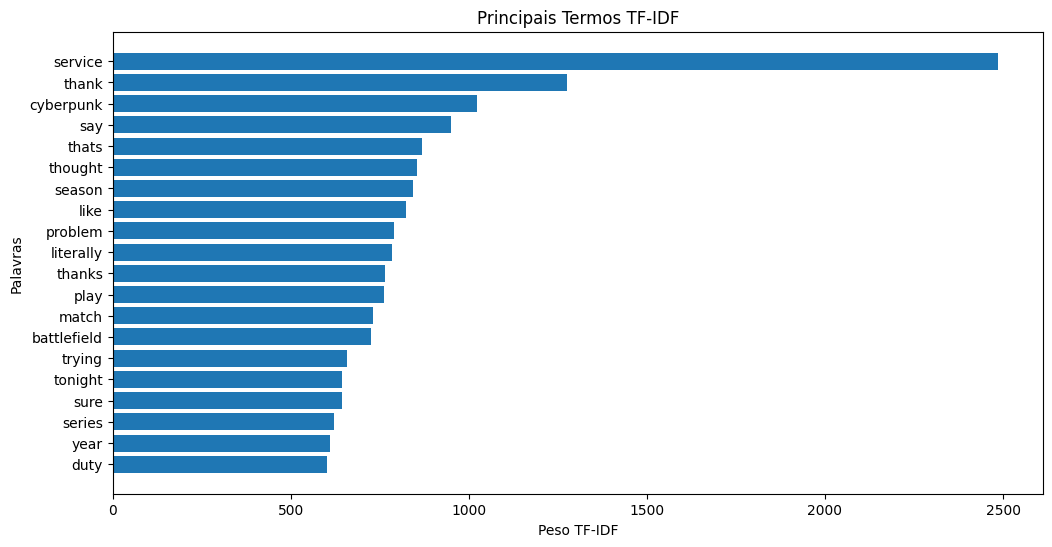

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Ordenar os termos pelo peso TF-IDF
sorted_items = sorted(word_freq.items(), key=lambda x: x[1], reverse=True)[:20]  # Pegando os 20 termos mais relevantes

# Separar palavras e valores
words, scores = zip(*sorted_items)

# Criar gráfico
plt.figure(figsize=(12, 6))
plt.barh(words[::-1], scores[::-1])  # Inverter para exibir do maior para o menor
plt.xlabel("Peso TF-IDF")
plt.ylabel("Palavras")
plt.title("Principais Termos TF-IDF")
plt.show()

In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
# Definir X (features) e y (rótulos)
vectorizer = CountVectorizer(tokenizer=word_tokenize, ngram_range=(1, 2))
X = vectorizer.fit_transform(df['clean_text'])
y = df['sentiment']

# Dividir os dados em treino e teste
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Treinar um classificador de Regressão Logística
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)

# Fazer previsões
y_pred = model.predict(X_test)

# Avaliação do modelo
print("📊 Accuracy:", accuracy_score(y_test, y_pred))
print("\n🔍 Classification Report:\n", classification_report(y_test, y_pred))

/usr/local/lib/python3.11/dist-packages/sklearn/feature_extraction/text.py:517: UserWarning: The parameter 'token_pattern' will not be used since 'tokenizer' is not None'
  warnings.warn(


📊 Accuracy: 0.8849923328221881

🔍 Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.91      0.91      4439
           1       0.83      0.93      0.87      4243
           2       0.91      0.86      0.88      3681
           3       0.94      0.81      0.87      2636

    accuracy                           0.88     14999
   macro avg       0.89      0.88      0.88     14999
weighted avg       0.89      0.88      0.88     14999



/usr/local/lib/python3.11/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


# Bônus - Count Vectorizer

``CountVectorizer`` e ``TfidfVectorizer`` são técnicas de vetorização de texto com abordagens distintas.

**CountVectorizer** transforma textos em uma matriz baseada na frequência absoluta das palavras, enquanto **TfidfVectorizer** ajusta esses valores atribuindo pesos maiores a palavras raras e menores a palavras comuns, utilizando a métrica TF-IDF (Term Frequency - Inverse Document Frequency).

Enquanto CountVectorizer é simples e eficaz quando a frequência bruta das palavras é suficiente, TfidfVectorizer melhora a precisão ao reduzir a influência de palavras muito frequentes, destacando termos mais relevantes para a diferenciação de textos.


---


- Use CountVectorizer quando a frequência absoluta das palavras for suficiente para a análise, como em modelos simples de análise de sentimento ou classificação de texto com grande volume de dados, onde a simplicidade e rapidez são essenciais.
- Já TfidfVectorizer é ideal quando a relevância dos termos precisa ser considerada, como em **sistemas de busca, detecção de spam ou classificação de tópicos**, pois reduz a influência de palavras muito comuns e destaca termos mais informativos.

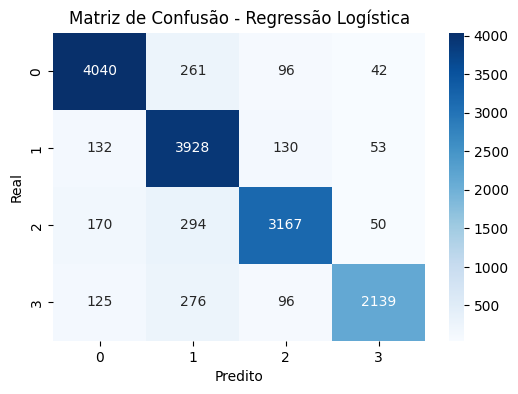

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Gerar a matriz de confusão
cm = confusion_matrix(y_test, y_pred)

# Definir os rótulos das classes (ajuste conforme necessário)
labels = sorted(df['sentiment'].unique())

# Criar o gráfico da matriz de confusão
plt.figure(figsize=(6, 4))
sns.heatmap(cm, annot=True, fmt='d', cmap="Blues", xticklabels=labels, yticklabels=labels)

# Configurações do gráfico
plt.xlabel("Predito")
plt.ylabel("Real")
plt.title("Matriz de Confusão - Regressão Logística")
plt.show()